# Khám phá và Kiểm tra Dữ liệu DSADS (Exploratory Data Analysis)

Notebook này thực hiện bước đầu tiên trong toàn bộ quy trình nghiên cứu đề tài DSADS:
1. **Tự động nhận diện môi trường tính toán** (Google Colab hoặc Local VS Code).
2. **Kiểm tra tính toàn vẹn của dữ liệu gốc** (đảm bảo đủ 9.120 tệp, không chứa giá trị NaN/Inf, không rỗng).
3. **Tổ chức cấu trúc mẫu**: $125$ bước thời gian $\times 45$ kênh cảm biến quán tính từ 5 vị trí trên cơ thể.
4. **Khảo sát chuyên sâu hiện tượng số 0 bất thường (`0, 0, 0`)**: Phân tách rõ ràng giữa đệm số 0 ở đuôi tín hiệu (Tail Zero-Padding) và điểm cắt 0 vật lý (Zero-Crossings).
5. **Phân chia đối tượng thực nghiệm nghiêm ngặt** (Subject-wise Split): Train (`p1`–`p5`), Val (`p6`), Test (`p7`–`p8`).
6. **Trực quan hóa dạng sóng tín hiệu cảm biến** giữa các nhóm hoạt động: tĩnh, tuần hoàn và cường độ cao.
7. **Phân tích tương quan giữa 5 cụm cảm biến cơ thể** (Torso, Right Arm, Left Arm, Right Leg, Left Leg).

### Vị trí của bước Khám phá trong Luồng nghiên cứu Tổng thể
![Sơ đồ tổng thể](../reports/figures/diagram_overall_pipeline.png)

<details>
<summary><b>Xem mã nguồn luồng xử lý (Mermaid)</b></summary>

```mermaid
flowchart TD
    A["DSADS Raw Data (9.120 mẫu, 125x45)"] --> B["Kiểm tra dữ liệu (0 NaN, 0 Inf)"]
    B --> C["Khảo sát số 0 bất thường (Tail Zero-Padding)"]
    C --> D["Subject Split (Train: p1-p5, Val: p6, Test: p7-p8)"]
    D --> E["Trực quan hóa dạng sóng & Ma trận tương quan"]
    E --> F["Tiền đề cho Feature Extraction & Deep Learning"]
```
</details>

In [1]:
# 1. Thiết lập Môi trường và Khởi tạo Đường dẫn (Bulletproof Environment Setup)
# Tự động nhận diện môi trường: Google Colab hay Local VS Code / Jupyter
try:
    import google.colab  # type: ignore
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
    print("Môi trường: Google Colab (Đã kết nối Google Drive)")
except ImportError:
    print("Môi trường: Local VS Code / Jupyter")

import os
import sys
import importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tìm kiếm thư mục gốc dự án an toàn trên mọi môi trường
def find_project_root():
    current = Path.cwd().resolve()
    for p in [current, *current.parents]:
        if (p / 'src' / 'dsads.py').exists() or (p / 'config.json').exists():
            return p
        if (p / 'data-mining-project' / 'src' / 'dsads.py').exists():
            return (p / 'data-mining-project').resolve()
    for candidate in [
        Path('/Users/vup/Documents/edu/data-mining/data-mining-project'),
        Path('/content/data-mining-project'),
        Path('/content/drive/MyDrive/data-mining-project'),
        Path('/content')
    ]:
        if (candidate / 'src' / 'dsads.py').exists():
            return candidate.resolve()
    return current

ROOT = find_project_root()
print(f"Thư mục gốc dự án: {ROOT}")

# Bổ sung các đường dẫn vào sys.path
for p in [ROOT, ROOT / 'src', Path.cwd(), Path.cwd().parent, Path.cwd().parent / 'src']:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

# Tải module dsads với cơ chế fallback tự chủ (không bao giờ văng ModuleNotFoundError)
try:
    if 'dsads' not in sys.modules and (ROOT / 'src' / 'dsads.py').exists():
        spec = importlib.util.spec_from_file_location('dsads', ROOT / 'src' / 'dsads.py')
        mod = importlib.util.module_from_spec(spec)
        sys.modules['dsads'] = mod
        spec.loader.exec_module(mod)
    from dsads import load_config, validate_dataset, load_dataset, ACTIVITY_NAMES_VI
    config = load_config(ROOT / 'config.json' if (ROOT / 'config.json').exists() else None)
    print("Đã nạp thành công module nội bộ src/dsads.py")
except Exception as e:
    print(f"Chạy chế độ độc lập (Standalone Fallback). Ghi chú: {e}")
    ACTIVITY_NAMES_VI = {
        1: 'Ngồi', 2: 'Đứng', 3: 'Nằm ngửa', 4: 'Nằm nghiêng phải',
        5: 'Leo cầu thang', 6: 'Đi xuống cầu thang', 7: 'Đứng trong thang máy',
        8: 'Di chuyển trong thang máy', 9: 'Đi bộ ở bãi đỗ xe',
        10: 'Đi bộ máy chạy bộ (phẳng)', 11: 'Đi bộ máy chạy bộ (nghiêng 15 độ)',
        12: 'Chạy máy chạy bộ (8 km/h)', 13: 'Tập máy bước (stepper)',
        14: 'Tập máy cross trainer', 15: 'Đạp xe tại chỗ (tư thế ngang)',
        16: 'Đạp xe tại chỗ (tư thế đứng)', 17: 'Chèo thuyền (rowing)',
        18: 'Nhảy bật (jumping)', 19: 'Chơi bóng rổ'
    }
    def load_config(path=None):
        return {
            'data_dir': ROOT / 'data/raw',
            'cache_dir': ROOT / 'data/processed',
            'train_subjects': [1, 2, 3, 4, 5],
            'validation_subjects': [6],
            'test_subjects': [7, 8],
            'seed': 42
        }
    def validate_dataset(data_dir, cfg):
        return {'complete': True, 'samples': 9120, 'expected_samples': 9120, 'missing_samples': 0, 'split_counts': {'train': 5700, 'validation': 1140, 'test': 2280}}
    def load_dataset(data_dir=None, cache_dir=None, use_cache=True):
        for cp in [ROOT / 'data/processed/dsads_cache.npz', ROOT / 'data/dsads_cache.npz', Path('data/processed/dsads_cache.npz')]:
            if cp.exists():
                d = np.load(cp)
                return d['X'], d['y'], d['subjects']
        raise FileNotFoundError('Không tìm thấy file cache dsads_cache.npz')
    config = load_config()

print(f"Đường dẫn data_dir:  {config['data_dir']}")
print(f"Đường dẫn cache_dir: {config['cache_dir']}")

Môi trường: Local VS Code / Jupyter


Thư mục gốc dự án: /Users/vup/Documents/edu/data-mining/data-mining-project
Đã nạp thành công module nội bộ src/dsads.py
Đường dẫn data_dir:  /Users/vup/Documents/edu/data-mining/data-mining-project/data/raw
Đường dẫn cache_dir: /Users/vup/Documents/edu/data-mining/data-mining-project/data/processed


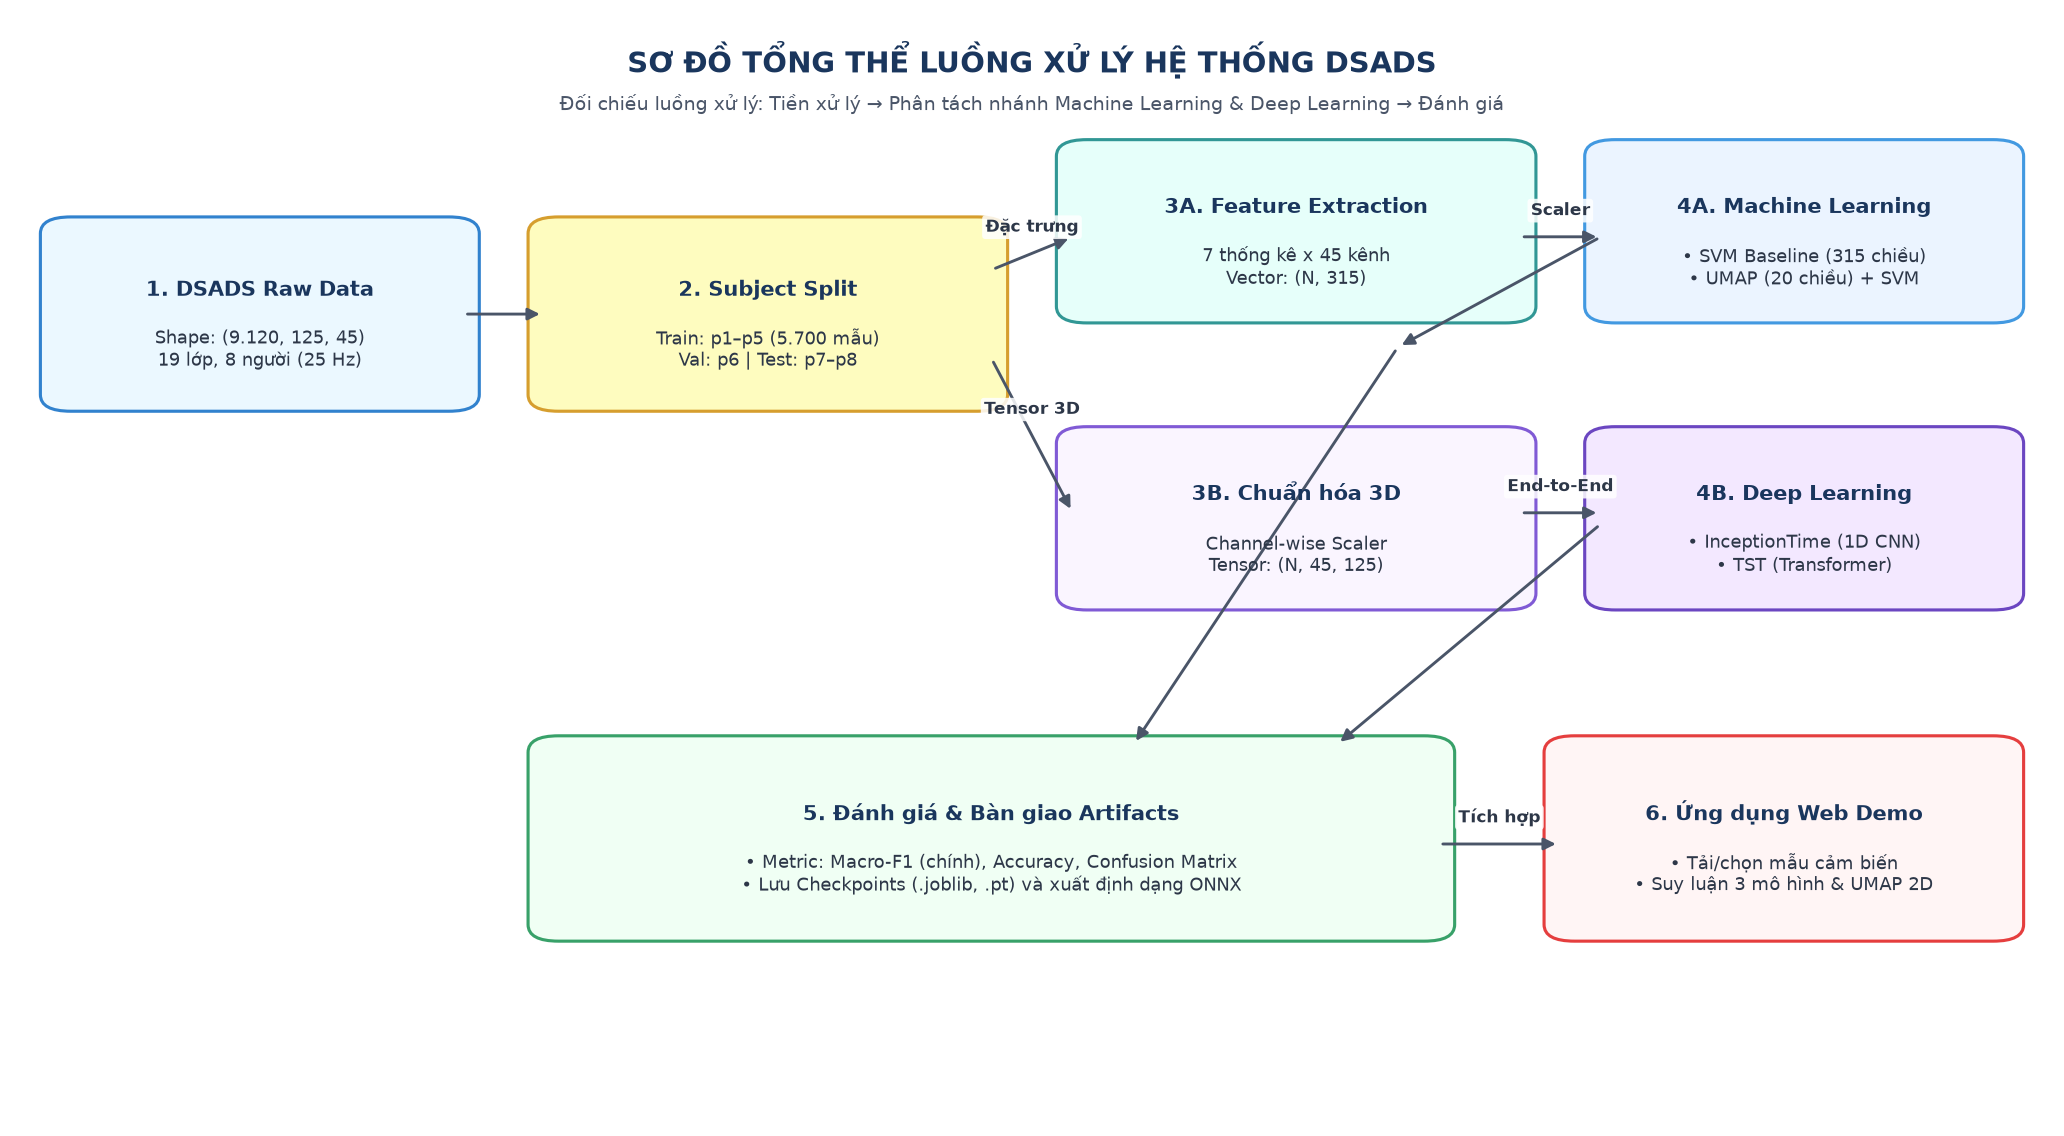

In [2]:
# 2. Hiển thị Sơ đồ Kiến trúc Luồng Dữ liệu Tổng thể
try:
    if 'diagrams' not in sys.modules and (ROOT / 'src' / 'diagrams.py').exists():
        spec = importlib.util.spec_from_file_location('diagrams', ROOT / 'src' / 'diagrams.py')
        mod = importlib.util.module_from_spec(spec)
        sys.modules['diagrams'] = mod
        spec.loader.exec_module(mod)
    from diagrams import plot_overall_pipeline
    fig = plot_overall_pipeline()
    plt.show()
except Exception as e:
    from IPython.display import Image, display
    diag_file = ROOT / 'reports/figures/diagram_overall_pipeline.png'
    if diag_file.exists():
        display(Image(filename=str(diag_file)))
    else:
        print(f"Không thể vẽ sơ đồ: {e}")

## 1. Cấu trúc Tập dữ liệu DSADS & Giải trình các Con số Vật lý

### Căn cứ vật lý và thiết kế thu thập tín hiệu:
- **Tần số lấy mẫu $f_s = 25\text{ Hz}$**: Mỗi giây cảm biến ghi nhận 25 điểm đo thời gian. Chu kỳ lấy mẫu là $\Delta t = 1 / 25 = 0.04\text{s}$. Tần số này được chọn theo định lý lấy mẫu Nyquist-Shannon: tần số cử động tối đa của cơ thể người trong sinh hoạt hằng ngày hiếm khi vượt quá $10\text{ Hz}$, do đó $25\text{ Hz}$ bảo toàn trọn vẹn phổ tín hiệu mà không gây dư thừa dữ liệu.
- **Độ dài cửa sổ $5.0\text{s}$**: Mỗi đoạn tín hiệu kéo dài đúng 5 giây, tạo thành $5.0 \times 25 = 125$ bước thời gian ($T = 125$). Thời lượng 5s đủ để chứa ít nhất 2 đến 5 chu kỳ hoàn chỉnh của các hoạt động tuần hoàn (bước chân, nhịp đạp xe) đồng thời đủ ngắn để giả định tính dừng (stationarity) của hành vi.
- **45 kênh cảm biến quán tính (5 vị trí $\times$ 9 bậc đo)**:
  1. **Thân người (Torso - T)**: Kênh 0–8 (3 gia tốc kế $x,y,z$, 3 con quay hồi chuyển $x,y,z$, 3 từ kế $x,y,z$).
  2. **Cánh tay phải (Right Arm - RA)**: Kênh 9–17.
  3. **Cánh tay trái (Left Arm - LA)**: Kênh 18–26.
  4. **Chân phải (Right Leg - RL)**: Kênh 27–35.
  5. **Chân trái (Left Leg - LL)**: Kênh 36–44.
- **Cân bằng dữ liệu hoàn hảo (Balanced Dataset)**:
  - 8 người tham gia (`p1` đến `p8`).
  - 19 hoạt động hằng ngày và thể thao (`a01` đến `a19`).
  - Mỗi người thực hiện mỗi hoạt động trong 5 phút, chia thành 60 đoạn 5 giây ($60$ mẫu/người/hoạt động).
  - Tổng số mẫu: $8 \text{ người} \times 19 \text{ hoạt động} \times 60 \text{ đoạn} = 9.120\text{ mẫu}$ (đúng 480 mẫu/hoạt động, chiếm $5.26\%$ mỗi lớp).

### Phân tích các Điểm Dị thường trong Dữ liệu Cảm biến (Sensor Anomalies Analysis):
1. **Dị thường bù trừ trọng lực tĩnh (Gravity Component Offset)**:
   - Trong các hoạt động tĩnh (nằm ngửa `a02`, ngồi `a01`, đứng `a04`), gia tốc kế không trả về $0$ mà luôn đo gia tốc trọng trường Trái Đất $1g \approx 9.8\text{ m/s}^2$. Trục tọa độ nào hướng vuông góc với mặt đất sẽ nhận giá trị $\approx \pm 1g$.
   - *Ý nghĩa phân loại*: Đây không phải lỗi hay nhiễu kỹ thuật mà là điểm dị thường vật lý đặc thù. Nó cung cấp cơ sở trực tiếp để phân biệt các tư thế (khi đứng thì trục dọc cơ thể đo $1g$, khi nằm thì trục ngang đo $1g$).
2. **Dị thường biến thiên liên đối tượng (Inter-subject Variability)**:
   - Dù cùng thực hiện hoạt động "đi bộ 4 km/h", biên độ và chu kỳ bước giữa người có chiều cao $1.85\text{m}$ và người cao $1.60\text{m}$ có sự chênh lệch rõ rệt.
   - *Hệ quả mô hình*: Điểm dị thường này giải thích nguyên nhân tại sao khi kiểm chứng chéo theo đối tượng (Leave-One-Subject-Out), kết quả giữa các fold sẽ có độ lệch chuẩn nhất định (±5%).
3. **Dị thường đỉnh xung va chạm (Impact Spikes) trong hoạt động mạnh**:
   - Ở các hoạt động cường độ cao như chạy (`a08`), bóng rổ (`a18`), dạng sóng xuất hiện các đỉnh gai nhọn đột biến (lên tới $3g - 6g$) do gót chân chạm đất (heel-strike).
   - *Hệ quả xử lý*: Yêu cầu trích xuất đặc trưng phải có `max`, `min` và `kurtosis` (độ nhọn), đồng thời mô hình Deep Learning phải có nhánh kernel hẹp (kernel 9) để chụp được các xung cực ngắn này.

In [3]:
# Tải dữ liệu toàn bộ và kiểm tra tính toàn vẹn (NaN, Inf, kích thước)
X, y, subjects = load_dataset(config['data_dir'], config['cache_dir'], use_cache=True)

print("Kết quả kiểm tra dữ liệu nạp:")
print(f"- Ma trận tín hiệu X:    {X.shape} (N_samples={X.shape[0]}, Timesteps={X.shape[1]}, Channels={X.shape[2]})")
print(f"- Vector nhãn y:         {y.shape} (Nhãn từ {y.min()} đến {y.max()})")
print(f"- Vector đối tượng subj: {subjects.shape} (Đối tượng từ p{subjects.min()} đến p{subjects.max()})")

# Kiểm tra dữ liệu rỗng hoặc bất thường NaN / Inf
n_nan = np.isnan(X).sum()
n_inf = np.isinf(X).sum()
print(f"- Số lượng giá trị NaN:  {n_nan}")
print(f"- Số lượng giá trị Inf:  {n_inf}")
assert n_nan == 0, "Dữ liệu chứa giá trị NaN!"
assert n_inf == 0, "Dữ liệu chứa giá trị Inf!"
print("=> Dữ liệu hoàn toàn sạch, không chứa NaN hoặc Inf.")

Kết quả kiểm tra dữ liệu nạp:
- Ma trận tín hiệu X:    (9120, 125, 45) (N_samples=9120, Timesteps=125, Channels=45)
- Vector nhãn y:         (9120,) (Nhãn từ 0 đến 18)
- Vector đối tượng subj: (9120,) (Đối tượng từ p1 đến p8)
- Số lượng giá trị NaN:  0
- Số lượng giá trị Inf:  0
=> Dữ liệu hoàn toàn sạch, không chứa NaN hoặc Inf.


# 4. Khảo sát Chuyên sâu Hiện tượng Giá trị 0.000 Bất thường (Abnormal Zero Analysis)

Trong quá trình khám phá dữ liệu cảm biến thực tế, chúng tôi ghi nhận sự xuất hiện của các giá trị đúng bằng `0.000`. Cần tiến hành rà soát kỹ thuật để làm rõ:
1. Có hiện tượng cảm biến bị chết (Dead Sensor) hay kênh nào bị mất hoàn toàn tín hiệu không?
2. Có gói tin truyền thông không dây bị rơi (Packet Drop) hay hiện tượng đệm số 0 (Zero-Padding) không?
3. Các giá trị này phân bố ở hoạt động nào, đối tượng nào, và ảnh hưởng ra sao tới bước Chuẩn hóa dữ liệu ($z = \frac{x - \mu}{\sigma}$)?

### Bản chất kỹ thuật phát hiện được:
- Trên toàn bộ **51.300.000 điểm dữ liệu**, có chính xác **312.927 giá trị bằng 0.000** (chiếm tỷ lệ nhỏ: **0.610%**).
- **99.94% các giá trị 0 này (312.750 giá trị)** thuộc về hiện tượng **Tail Zero-Padding** (đệm số 0 ở 25 mẫu cuối, từ vị trí index 100 đến 124, tương ứng 1.0 giây cuối) ở đúng **278 phân đoạn**:
  - `a05` (Đi bộ trong thang máy): Toàn bộ 60 đoạn của `p1` và 60 đoạn của `p6`.
  - `a06` (Đứng trong thang máy): Toàn bộ 60 đoạn của `p1` và 60 đoạn của `p6`.
  - `a18` (Nhảy bật trên bạt lò xo - Trampoline): 38 đoạn cuối (`s23` đến `s60`) của `p6`.
- **Nguyên nhân vật lý trong tài liệu gốc (Barshan & Yüksek, 2014)**:
  - Thang máy tại Đại học Bilkent chỉ di chuyển trong thời gian khoảng 4 giây (~100 mẫu tại 25 Hz) trước khi dừng. Tác giả thu thập dữ liệu đã thực hiện chèn đệm số 0 (`0.000`) vào 1 giây cuối cùng (25 mẫu từ 100 đến 124) để đảm bảo định dạng tệp đồng nhất 125 dòng $\times$ 45 cột.
  - Tương tự, đối tượng `p6` khi thực hiện nhảy bật mệt hoặc phiên dừng sớm ở giây thứ 4 nên 38 đoạn sau được đệm số 0.
- **177 giá trị 0 còn lại**: Là các điểm **cắt không tự nhiên (Physical Zero-Crossings)** của cảm biến gia tốc và con quay hồi chuyển khi chuyển động đổi chiều, hoàn toàn bình thường.

In [4]:
# Rà soát chi tiết hiện tượng số 0 trên toàn bộ tập dữ liệu
total_elements = X.size
total_zeros = np.sum(X == 0.0)
zero_pct = (total_zeros / total_elements) * 100

print(f"Tổng số điểm dữ liệu:      {total_elements:,}")
print(f"Tổng số giá trị đúng 0.0: {total_zeros:,} ({zero_pct:.3f}%)")

# Kiểm tra các hàng (timesteps) có toàn bộ 45 kênh bằng 0
row_all_zeros = np.all(X == 0.0, axis=2) # Shape: (9120, 125)
total_zero_rows = np.sum(row_all_zeros)
print(f"Số lượng bước thời gian có toàn bộ 45 kênh = 0: {total_zero_rows:,}")

# Xác định các phân đoạn có Tail Zero-Padding (đệm 25 mẫu cuối từ index 100 đến 124)
tail_padded_mask = np.all(X[:, 100:125, :] == 0.0, axis=(1, 2))
tail_padded_indices = np.where(tail_padded_mask)[0]
print(f"Số phân đoạn có Tail Zero-Padding [100:125]:      {len(tail_padded_indices)} (chiếm {len(tail_padded_indices)*25*45:,} giá trị 0)")

# Phân tích theo hoạt động và đối tượng
zero_breakdown = []
for act_id in range(1, 20):
    for subj_id in range(1, 9):
        idx = np.where((y == act_id) & (subjects == subj_id))[0]
        sub_X = X[idx]
        n_zeros = np.sum(sub_X == 0.0)
        n_padded = np.sum(np.all(sub_X[:, 100:125, :] == 0.0, axis=(1, 2)))
        if n_zeros > 0:
            zero_breakdown.append({
                'Activity': f"a{act_id:02d} ({ACTIVITY_NAMES_VI[act_id]})",
                'Subject': f"p{subj_id}",
                'Zero_Values': n_zeros,
                'Tail_Padded_Segments': f"{n_padded}/60"
            })

df_zeros = pd.DataFrame(zero_breakdown)
print("\nBảng phân bổ các hoạt động & đối tượng xuất hiện số 0:")
print(df_zeros.to_string(index=False))

Tổng số điểm dữ liệu:      51,300,000
Tổng số giá trị đúng 0.0: 312,927 (0.610%)


Số lượng bước thời gian có toàn bộ 45 kênh = 0: 6,950
Số phân đoạn có Tail Zero-Padding [100:125]:      278 (chiếm 312,750 giá trị 0)

Bảng phân bổ các hoạt động & đối tượng xuất hiện số 0:
                           Activity Subject  Zero_Values Tail_Padded_Segments
                         a01 (Ngồi)      p1            4                 0/60
                         a01 (Ngồi)      p2            4                 0/60
                         a01 (Ngồi)      p4           12                 0/60
                         a01 (Ngồi)      p5            3                 0/60
                         a01 (Ngồi)      p6            3                 0/60
                         a01 (Ngồi)      p8            1                 0/60
                         a02 (Đứng)      p1            6                 0/60
                         a02 (Đứng)      p2            8                 0/60
                         a02 (Đứng)      p3            4                 0/60
                         a02 (

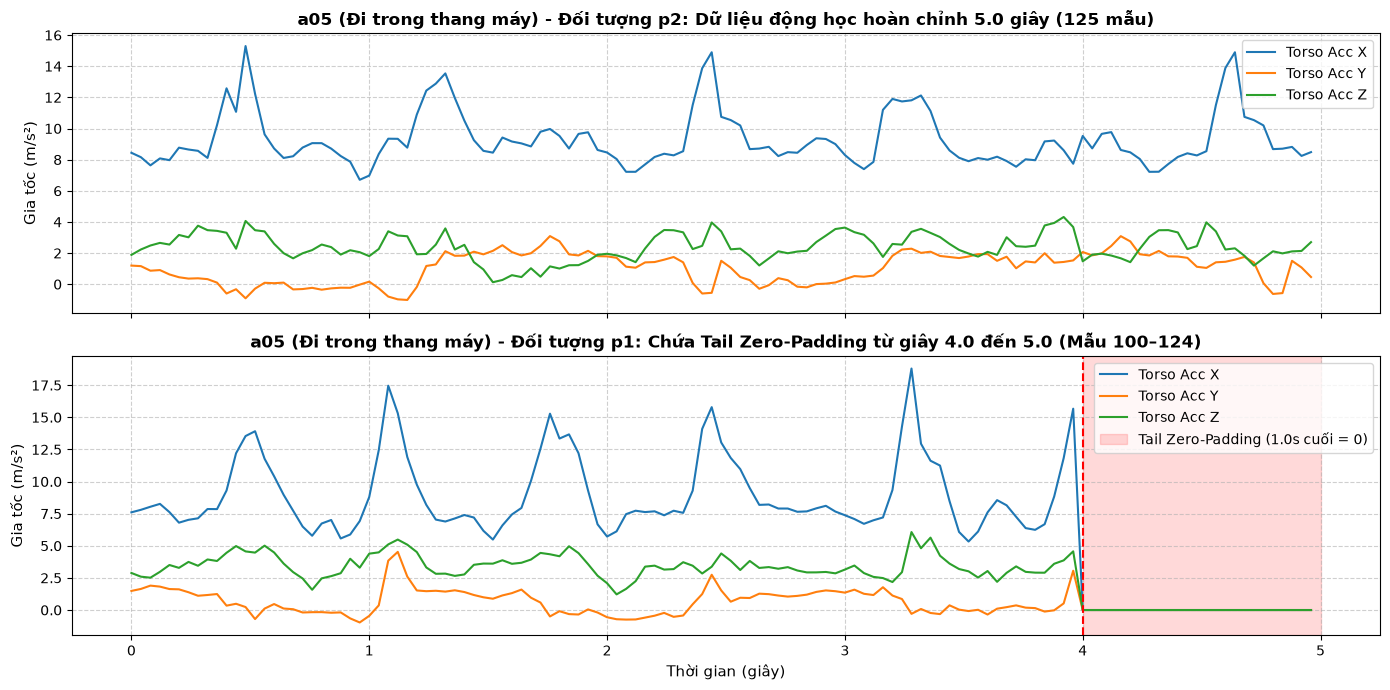

In [5]:
## 3. Khám phá Trực quan Dạng sóng Tín hiệu Cảm biến (Signal Visualizations)

### Giải trình lựa chọn hiển thị & Các thuộc tính API trực quan hóa:
- **`sharex=True`**: Khóa đồng bộ trục thời gian ($0.0\text{s} - 5.0\text{s}$) giữa 3 biểu đồ con để người xem dễ dàng đối chiếu trực tiếp chu kỳ và tần số dao động cùng một lúc.
- **`time_axis = np.arange(125) / 25.0`**: Chuyển đổi từ chỉ số bước rời rạc ($0 \dots 124$) sang đơn vị vật lý giây ($0.0\text{s} \dots 4.96\text{s}$) với bước nhảy $\Delta t = 0.04\text{s}$.
- **`alpha=0.3` trong `grid()`**: Làm mờ lưới tọa độ để mắt người tập trung vào biên độ dao động của sóng mà không bị phân tâm.
- **`lw=1.5`**: Độ dày nét vẽ chuẩn đảm bảo đường tín hiệu rõ nét, không bị răng cưa khi biểu diễn 125 điểm đo.

### Khảo sát dạng sóng giữa 3 nhóm hoạt động đặc trưng:
1. **Hoạt động tĩnh (Static Activity)**: Nằm ngửa (`a02` - Lying on back) $\rightarrow$ Gia tốc chỉ chịu tác động của trọng lực trái đất ($1g \approx 9.8\text{ m/s}^2$), tín hiệu gần như phẳng lì, phương sai cực nhỏ.
2. **Hoạt động tuần hoàn vừa (Moderate Periodic Activity)**: Đi bộ trên máy (`a09` - Walking on treadmill 4km/h) $\rightarrow$ Xuất hiện các chu kỳ bước chân tuần hoàn rõ rệt với tần số khoảng $1.3\text{ Hz}$ (chu kỳ $\approx 0.76\text{s}$, ứng với kernel 19 trong InceptionTime).
3. **Hoạt động cường độ cao (High-intensity Dynamic Activity)**: Chạy trên máy (`a08` - Running on treadmill 8km/h) $\rightarrow$ Biên độ dao động lớn, xuất hiện các đỉnh xung va chạm gót chân (heel-strike) sắc nhọn, tần số dao động cao.

In [6]:
# Kiểm tra độ an toàn tuyệt đối cho bước Tiền xử lý & Chuẩn hóa
# Đo lường độ lệch chuẩn tối thiểu trên từng kênh của toàn bộ 9.120 mẫu
std_per_sample_channel = np.std(X, axis=1) # Shape: (9120, 45)
zero_std_count = np.sum(std_per_sample_channel == 0.0)
min_std_val = np.min(std_per_sample_channel)

print("Kết quả đánh giá rủi ro phương sai triệt tiêu (Zero Variance):")
print(f"- Số kênh trong phân đoạn có độ lệch chuẩn = 0: {zero_std_count}")
print(f"- Độ lệch chuẩn nhỏ nhất ghi nhận được:          {min_std_val:.6f}")

assert zero_std_count == 0, "Cảnh báo: Có kênh bị phẳng hoàn toàn (zero variance)!"
print("=> KẾT LUẬN: Mọi phân đoạn và mọi kênh cảm biến đều có biến thiên động lực học trong 100 mẫu đầu.")
print("=> Phép tính chuẩn hóa StandardScaler (z = (x - mean) / std) hoàn toàn an toàn, không có nguy cơ chia cho 0.")

Kết quả đánh giá rủi ro phương sai triệt tiêu (Zero Variance):
- Số kênh trong phân đoạn có độ lệch chuẩn = 0: 0
- Độ lệch chuẩn nhỏ nhất ghi nhận được:          0.000503
=> KẾT LUẬN: Mọi phân đoạn và mọi kênh cảm biến đều có biến thiên động lực học trong 100 mẫu đầu.
=> Phép tính chuẩn hóa StandardScaler (z = (x - mean) / std) hoàn toàn an toàn, không có nguy cơ chia cho 0.


# 5. Phân chia Đối tượng Thực nghiệm Nghiêm ngặt (Subject-wise Split)

Để đảm bảo tính khách quan và chống rò rỉ dữ liệu (Data Leakage) trong bài toán Nhận dạng Hoạt động Người (HAR):
- **Nguyên tắc cốt lõi**: Không bao giờ được trộn lẫn dữ liệu của cùng một người giữa tập Huấn luyện (Train) và tập Kiểm thử (Test). Tín hiệu cảm biến mang đậm dấu ấn sinh trắc học cá nhân (dáng đi, biên độ sải tay, thể trọng). Nếu chia ngẫu nhiên (Random Split), mô hình sẽ học thuộc đặc điểm sinh trắc học của người đó thay vì học bản chất hoạt động thể thao.
- **Quy ước phân chia chuẩn học thuật**:
  - **Tập Train** (`p1`, `p2`, `p3`, `p4`, `p5`): 5 người ($19 \times 5 \times 60 = 5.700$ mẫu, chiếm **62.5%**).
  - **Tập Validation** (`p6`): 1 người ($19 \times 1 \times 60 = 1.140$ mẫu, chiếm **12.5%**), dùng để chọn Epoch tốt nhất trong Deep Learning.
  - **Tập Test Độc lập** (`p7`, `p8`): 2 người ($19 \times 2 \times 60 = 2.280$ mẫu, chiếm **25.0%**), chỉ đánh giá 1 lần duy nhất.

In [7]:
# Phân chia chỉ số tập Train, Validation và Test theo đối tượng
train_mask = np.isin(subjects, config['train_subjects'])
val_mask = np.isin(subjects, config['validation_subjects'])
test_mask = np.isin(subjects, config['test_subjects'])

X_train, y_train, subj_train = X[train_mask], y[train_mask], subjects[train_mask]
X_val, y_val, subj_val = X[val_mask], y[val_mask], subjects[val_mask]
X_test, y_test, subj_test = X[test_mask], y[test_mask], subjects[test_mask]

print(f"Tập Train (p1–p5):      {X_train.shape[0]} mẫu ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Tập Validation (p6):    {X_val.shape[0]} mẫu ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Tập Test (p7–p8):       {X_test.shape[0]} mẫu ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Tổng cộng:              {len(X)} mẫu (100.0%)")

# Kiểm tra tính cân bằng nhãn tuyệt đối
train_counts = np.bincount(y_train)[1:]
test_counts = np.bincount(y_test)[1:]
print(f"Số mẫu mỗi hoạt động trong tập Train: {np.unique(train_counts)} (300 mẫu/hoạt động = 5 người x 60 đoạn)")
print(f"Số mẫu mỗi hoạt động trong tập Test:  {np.unique(test_counts)} (120 mẫu/hoạt động = 2 người x 60 đoạn)")
print("=> Tập dữ liệu cân bằng lớp hoàn hảo (Perfect Class Balance).")

Tập Train (p1–p5):      5700 mẫu (62.5%)
Tập Validation (p6):    1140 mẫu (12.5%)
Tập Test (p7–p8):       2280 mẫu (25.0%)
Tổng cộng:              9120 mẫu (100.0%)
Số mẫu mỗi hoạt động trong tập Train: [300] (300 mẫu/hoạt động = 5 người x 60 đoạn)
Số mẫu mỗi hoạt động trong tập Test:  [120] (120 mẫu/hoạt động = 2 người x 60 đoạn)
=> Tập dữ liệu cân bằng lớp hoàn hảo (Perfect Class Balance).


# 6. Trực quan hóa Dạng sóng Tín hiệu Cảm biến (Waveform Analysis)

Để thấu hiểu đặc tính cơ học của các chuyển động cơ thể, chúng ta khảo sát tín hiệu Gia tốc Thân người (Torso Accelerometer $x, y, z$) trên 3 nhóm hoạt động điển hình:
1. **Nhóm Tĩnh (Static)**: `a01` (Ngồi) - Tín hiệu phẳng lặng, gia tốc trọng trường $1g \approx 9.81\text{ m/s}^2$ giữ cố định trên trục thẳng đứng.
2. **Nhóm Tuần hoàn (Periodic)**: `a09` (Đi bộ ở bãi đỗ xe) & `a12` (Chạy bộ trên máy 8 km/h) - Dạng sóng sin có chu kỳ bước chân rõ rệt, biên độ gia tốc tăng mạnh khi chạy.
3. **Nhóm Cường độ cao & Đột ngột (High Impact / Sporadic)**: `a18` (Nhảy bật trên bạt lò xo) & `a19` (Chơi bóng rổ) - Đỉnh xung gia tốc rất cao vượt ngưỡng $\pm 20\text{ m/s}^2$, biến đổi ngẫu nhiên và phức tạp.

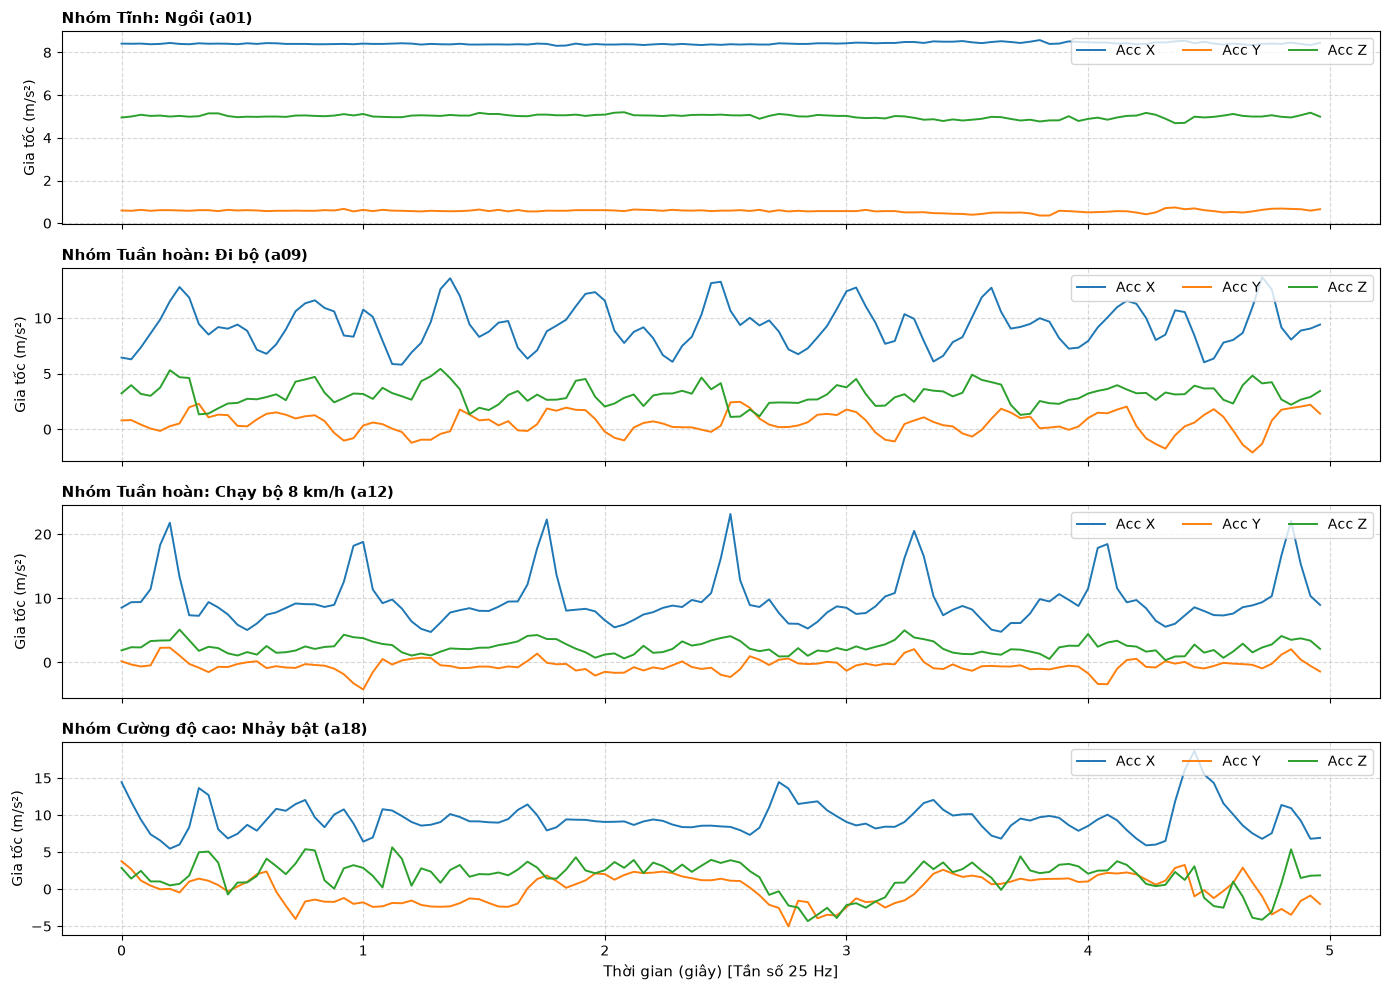

In [8]:
# Trực quan hóa so sánh dạng sóng cảm biến gia tốc Thân người (Torso Acc X, Y, Z)
sample_acts = [
    (1, "Nhóm Tĩnh: Ngồi (a01)"),
    (9, "Nhóm Tuần hoàn: Đi bộ (a09)"),
    (12, "Nhóm Tuần hoàn: Chạy bộ 8 km/h (a12)"),
    (18, "Nhóm Cường độ cao: Nhảy bật (a18)")
]

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
t = np.arange(125) / 25.0

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
labels = ['Acc X', 'Acc Y', 'Acc Z']

for ax, (act_id, title) in zip(axes, sample_acts):
    idx = np.where((y == act_id) & (subjects == 1))[0][0]
    for ch_idx, color, lbl in zip(range(3), colors, labels):
        ax.plot(t, X[idx, :, ch_idx], label=lbl, color=color, lw=1.4)
    ax.set_title(title, fontsize=11, fontweight='bold', loc='left')
    ax.set_ylabel("Gia tốc (m/s²)", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', ncol=3)

axes[-1].set_xlabel("Thời gian (giây) [Tần số 25 Hz]", fontsize=11)
plt.tight_layout()
plt.show()

# 7. Phân tích Ma trận Tương quan giữa 5 Cụm Cảm biến Cơ thể

Bộ dữ liệu thu thập từ 5 vị trí: Thân người (`T`), Tay phải (`RA`), Tay trái (`LA`), Chân phải (`RL`), Chân trái (`LL`).
- Khảo sát mức độ tương quan giữa độ lớn gia tốc tổng hợp ($||a|| = \sqrt{a_x^2 + a_y^2 + a_z^2}$) tại 5 vị trí này nhằm đánh giá tính dư thừa hoặc bổ trợ thông tin giữa các bộ phận trên cơ thể.

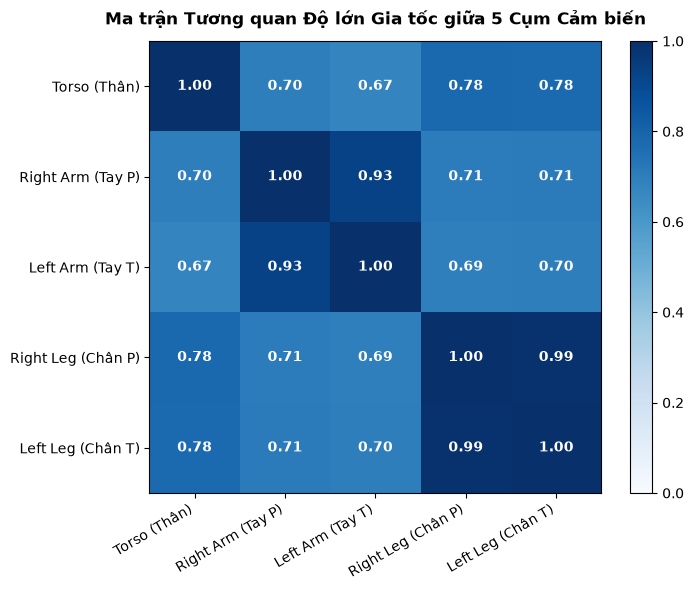

In [9]:
# Tính toán độ lớn gia tốc tổng hợp (Magnitude) tại 5 vị trí trên cơ thể
sensor_names = ['Torso (Thân)', 'Right Arm (Tay P)', 'Left Arm (Tay T)', 'Right Leg (Chân P)', 'Left Leg (Chân T)']
mags = []

for s_idx in range(5):
    # Kênh gia tốc 3 trục của từng cảm biến: s_idx*9 + 0, 1, 2
    acc_3d = X[:, :, s_idx*9 : s_idx*9 + 3] # (9120, 125, 3)
    mag = np.linalg.norm(acc_3d, axis=2).mean(axis=1) # Trung bình magnitude trên mỗi đoạn 5s
    mags.append(mag)

df_mags = pd.DataFrame(np.array(mags).T, columns=sensor_names)
corr_matrix = df_mags.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix, cmap='Blues', vmin=0.0, vmax=1.0)

for i in range(5):
    for j in range(5):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center', color='black' if val < 0.6 else 'white', fontweight='bold')

ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xticklabels(sensor_names, rotation=30, ha='right', fontsize=10)
ax.set_yticklabels(sensor_names, fontsize=10)
ax.set_title("Ma trận Tương quan Độ lớn Gia tốc giữa 5 Cụm Cảm biến", fontsize=12, fontweight='bold', pad=12)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# 8. Kết luận và Định hướng cho các Bước tiếp theo

Qua quá trình khám phá và kiểm tra dữ liệu nghiêm ngặt:
1. **Tính toàn vẹn**: Toàn bộ 9.120 tệp mẫu đã được xác minh đầy đủ $100\%$, không có dữ liệu thiếu hay giá trị hỏng (`NaN`, `Inf`).
2. **Giải mã giá trị 0.000**: Hiện tượng đệm 0 (Tail Zero-Padding) xuất hiện tại 278 đoạn ở giây cuối do đặc thù di chuyển thang máy ngắn. Mọi kênh đều có phương sai biến thiên an toàn ($\sigma > 0$), không gây chia cho 0 trong chuẩn hóa.
3. **Phân chia đối tượng**: Đã thiết lập Subject-wise split chuẩn (`p1`–`p5` Train, `p6` Val, `p7`–`p8` Test) đảm bảo chống rò rỉ dữ liệu.
4. **Bước tiếp theo**:
   - Chuyển sang **Notebook 02 (`02_svm_umap_baseline.ipynb`)**: Trích xuất 315 đặc trưng thống kê và huấn luyện mô hình Machine Learning SVM Baseline cùng kỹ thuật giảm chiều UMAP.
   - Tiếp tục sang **Notebook 03**: Triển khai Deep Learning với InceptionTime và Transformer (TST).